# ExtraaLearn Project

## Context

The EdTech industry has been surging in the past decade immensely, and according to a forecast, the Online Education market would be worth $286.62bn by 2023 with a compound annual growth rate (CAGR) of 10.26% from 2018 to 2023. The modern era of online education has enforced a lot in its growth and expansion beyond any limit. Due to having many dominant features like ease of information sharing, personalized learning experience, transparency of assessment, etc, it is now preferable to traditional education.

In the present scenario due to the Covid-19, the online education sector has witnessed rapid growth and is attracting a lot of new customers. Due to this rapid growth, many new companies have emerged in this industry. With the availability and ease of use of digital marketing resources, companies can reach out to a wider audience with their offerings. The customers who show interest in these offerings are termed as leads. There are various sources of obtaining leads for Edtech companies, like

* The customer interacts with the marketing front on social media or other online platforms.
* The customer browses the website/app and downloads the brochure
* The customer connects through emails for more information.

The company then nurtures these leads and tries to convert them to paid customers. For this, the representative from the organization connects with the lead on call or through email to share further details.

## Objective

ExtraaLearn is an initial stage startup that offers programs on cutting-edge technologies to students and professionals to help them upskill/reskill. With a large number of leads being generated on a regular basis, one of the issues faced by ExtraaLearn is to identify which of the leads are more likely to convert so that they can allocate resources accordingly. You, as a data scientist at ExtraaLearn, have been provided the leads data to:
* Analyze and build an ML model to help identify which leads are more likely to convert to paid customers,
* Find the factors driving the lead conversion process
* Create a profile of the leads which are likely to convert


## Data Description

The data contains the different attributes of leads and their interaction details with ExtraaLearn. The detailed data dictionary is given below.


**Data Dictionary**
* ID: ID of the lead
* age: Age of the lead
* current_occupation: Current occupation of the lead. Values include 'Professional','Unemployed',and 'Student'
* first_interaction: How did the lead first interacted with ExtraaLearn. Values include 'Website', 'Mobile App'
* profile_completed: What percentage of profile has been filled by the lead on the website/mobile app. Values include Low - (0-50%), Medium - (50-75%), High (75-100%)
* website_visits: How many times has a lead visited the website
* time_spent_on_website: Total time spent on the website
* page_views_per_visit: Average number of pages on the website viewed during the visits.
* last_activity: Last interaction between the lead and ExtraaLearn.
    * Email Activity: Seeking for details about program through email, Representative shared information with lead like brochure of program , etc
    * Phone Activity: Had a Phone Conversation with representative, Had conversation over SMS with representative, etc
    * Website Activity: Interacted on live chat with representative, Updated profile on website, etc

* print_media_type1: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Newspaper.
* print_media_type2: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Magazine.
* digital_media: Flag indicating whether the lead had seen the ad of ExtraaLearn on the digital platforms.
* educational_channels: Flag indicating whether the lead had heard about ExtraaLearn in the education channels like online forums, discussion threads, educational websites, etc.
* referral: Flag indicating whether the lead had heard about ExtraaLearn through reference.
* status: Flag indicating whether the lead was converted to a paid customer or not.

## Importing necessary libraries and data

In [ ]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report, precision_recall_curve, recall_score, auc, roc_curve, roc_auc_score
)
from sklearn import tree
# to suppress warnings
import warnings

warnings.filterwarnings("ignore")

## Data Overview

- Observations
- Sanity checks

In [ ]:
# give access to google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# @title
data = pd.read_csv("/content/drive/MyDrive/00 Great Learning/ExtraaLearn.csv")

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4612 entries, 0 to 4611
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     4612 non-null   object 
 1   age                    4612 non-null   int64  
 2   current_occupation     4612 non-null   object 
 3   first_interaction      4612 non-null   object 
 4   profile_completed      4612 non-null   object 
 5   website_visits         4612 non-null   int64  
 6   time_spent_on_website  4612 non-null   int64  
 7   page_views_per_visit   4612 non-null   float64
 8   last_activity          4612 non-null   object 
 9   print_media_type1      4612 non-null   object 
 10  print_media_type2      4612 non-null   object 
 11  digital_media          4612 non-null   object 
 12  educational_channels   4612 non-null   object 
 13  referral               4612 non-null   object 
 14  status                 4612 non-null   int64  
dtypes: f

In [ ]:
data.head()

,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
0,EXT001,57,Unemployed,Website,High,7,1639,1.861,Website Activity,Yes,No,Yes,No,No,1
1,EXT002,56,Professional,Mobile App,Medium,2,83,0.320,Website Activity,No,No,No,Yes,No,0
2,EXT003,52,Professional,Website,Medium,3,330,0.074,Website Activity,No,No,Yes,No,No,0
3,EXT004,53,Unemployed,Website,High,4,464,2.057,Website Activity,No,No,No,No,No,1
4,EXT005,23,Student,Website,High,4,600,16.914,Email Activity,No,No,No,No,No,0


In [ ]:
data.nunique()

,0
ID,4612
age,46
current_occupation,3
first_interaction,2
profile_completed,3
website_visits,27
time_spent_on_website,1623
page_views_per_visit,2414
last_activity,3
print_media_type1,2


Observations


* There is no missing data within this data set of 15 columns and 4612 observations
*   Only one column ID has 4612 unique entries which means that it can be dropped as it will not add any value to our analysis.



## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**
1. Leads will have different expectations from the outcome of the course and the current occupation may play a key role in getting them to participate in the program. Find out how current occupation affects lead status.
2. The company's first impression on the customer must have an impact. Do the first channels of interaction have an impact on the lead status?
3. The company uses multiple modes to interact with prospects. Which way of interaction works best?
4. The company gets leads from various channels such as print media, digital media, referrals, etc. Which of these channels have the highest lead conversion rate?
5. People browsing the website or mobile application are generally required to create a profile by sharing their personal data before they can access additional information.Does having more details about a prospect increase the chances of conversion?

## Data Preprocessing

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

In [ ]:
# to get rid of the ID column
df= data.drop('ID', axis=1)

In [ ]:
#Check new data set
df.head()

,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
0,57,Unemployed,Website,High,7,1639,1.861,Website Activity,Yes,No,Yes,No,No,1
1,56,Professional,Mobile App,Medium,2,83,0.320,Website Activity,No,No,No,Yes,No,0
2,52,Professional,Website,Medium,3,330,0.074,Website Activity,No,No,Yes,No,No,0
3,53,Unemployed,Website,High,4,464,2.057,Website Activity,No,No,No,No,No,1
4,23,Student,Website,High,4,600,16.914,Email Activity,No,No,No,No,No,0


## EDA

- It is a good idea to explore the data once again after manipulating it.

In [ ]:
# separates numerical columns from categorical variables

numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(exclude=np.number).columns

In [ ]:
#descriptive statistics on numerical columns
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age,4612.0,46.201214,13.161454,18.0,36.00000,51.000,57.00000,63.000
website_visits,4612.0,3.566782,2.829134,0.0,2.00000,3.000,5.00000,30.000
time_spent_on_website,4612.0,724.011275,743.828683,0.0,148.75000,376.000,1336.75000,2537.000
page_views_per_visit,4612.0,3.026126,1.968125,0.0,2.07775,2.792,3.75625,18.434
status,4612.0,0.298569,0.457680,0.0,0.00000,0.000,1.00000,1.000


Observations


*   Average lead is 46 years old, plus or minus 13 years. The youngest lead is 18 years-old and oldest 63 years-old. There a clearly wide age gap which might have implications on engagement
*   The average number of website visits is 3.5. Given that the maximum is 30 and that lower 75% of Leads visit the site about 5 times, it shows that there are outliers that would make the distribution plot right-skewed.

*   Average time spent on website is 724 plus or minus approximately 744. The standard deviation that is greater than mean shows that there is a huge difference in time spent on website among leads. The upper  50% spent significantly more time on the website than the lower 50%. There is bimodal distribution.
*   Average number of pages viewed per visit is 3. There is also a large standard deviation from the mean of about 2 which is 2/3 of the mean. The maximum number of page views of 18 and the 75% percentile viewing about 3.8 shows that the data is left skewed by outliers in higher range. The 25 % of leads who view more pages per visit see significantly more pages per visit than the lower 75%. A large bulk of leads who visit the website see less than 5 pages per visit.



*   The status mean of 0.29 signifies that status of 29% of the leads is 1, hence 1337 out of 4612 leads became paying customers for ExtraaLearn.










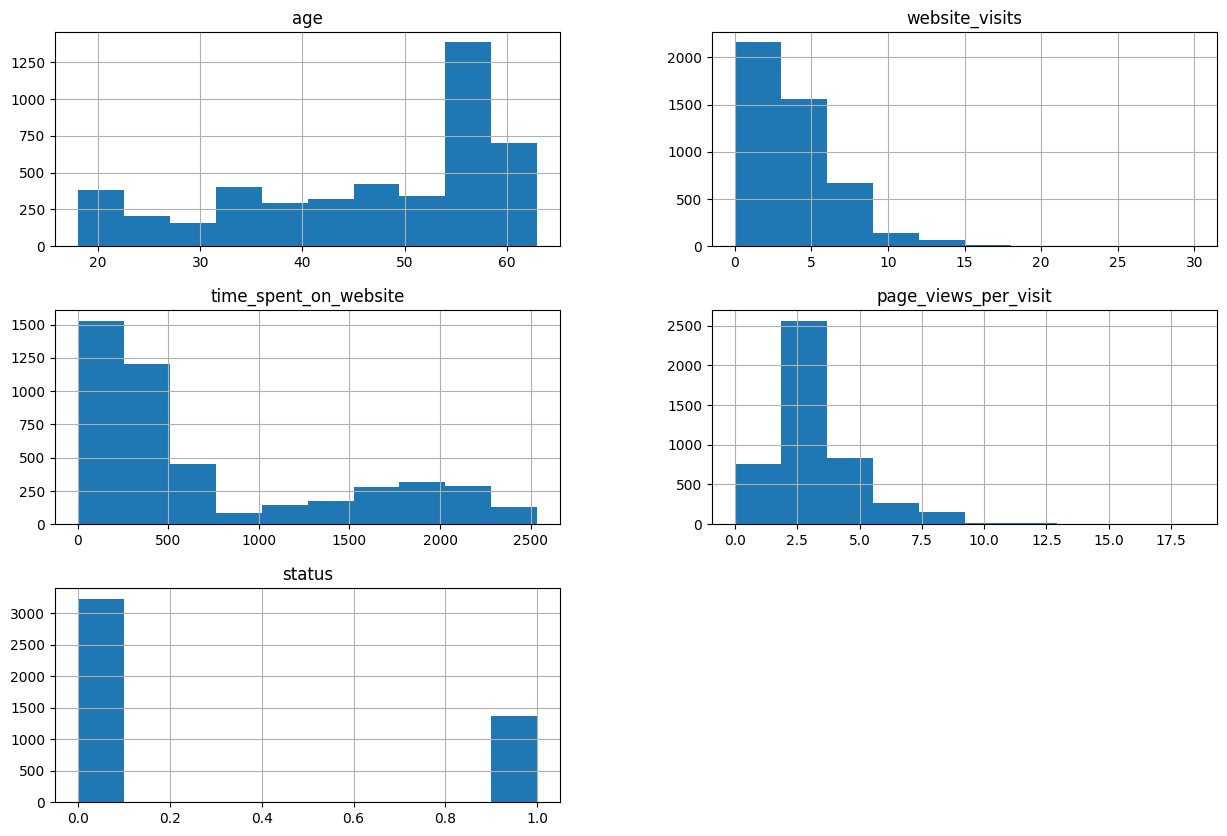

In [ ]:
#plots showing distribution of numerical columns
df[numerical_columns].hist(figsize=(15,10))
plt.show()

Observations

*   There is a left-skew in Age distribution given that the a large number of leads who are above 50


*   Majority of leads status is 0 meaning that many aren't turning into paid customers
*   Many of the leads visit the website between 0 and 5 times.



*   The highest frequency of page views is 2.5.


*   About 3200 of 4612 leads status is 0 meaning that they don't turn into paid customers.
*   There are two clear groups in time_spent_on_website. A large group majority who spend close to 500 and less time units on the website. Another group that spends between 750 and 2500 times units on the website





In [ ]:
for i in categorical_columns:
  print(df[i].value_counts(normalize=True))
  print

current_occupation
Professional    0.567216
Unemployed      0.312446
Student         0.120338
Name: proportion, dtype: float64
first_interaction
Website       0.551171
Mobile App    0.448829
Name: proportion, dtype: float64
profile_completed
High      0.490893
Medium    0.485906
Low       0.023200
Name: proportion, dtype: float64
last_activity
Email Activity      0.493929
Phone Activity      0.267563
Website Activity    0.238508
Name: proportion, dtype: float64
print_media_type1
No     0.892238
Yes    0.107762
Name: proportion, dtype: float64
print_media_type2
No     0.94948
Yes    0.05052
Name: proportion, dtype: float64
digital_media
No     0.885733
Yes    0.114267
Name: proportion, dtype: float64
educational_channels
No     0.847138
Yes    0.152862
Name: proportion, dtype: float64
referral
No     0.979835
Yes    0.020165
Name: proportion, dtype: float64




*   Current_occupation - about 56% of leads are professionals while 31% are unemployed and only 12% are students


*   First_interaction for 55% of the leads takes place through website while remaaning 45% occurs through the mobile app


*   Levels of profile_completed are approximately 49% for High and Medium and 2% for the Low.
*   Last_activity of leads contact with ExtaaLearn is 49% Email Activity, 27% call Activity and 23% website Activity. This shows that at least 80% of the leads have greater interaction with ExtraaLearn beyond website visit.


*   print_media_type1 and print_media_type2 have very high precentages of No about 90% and 95%, respectively. this show that these percentages haven't seen ExtaaLearn ads in either Newspapers or Magazines.
*   digital_media, educational_channels and referrals also have very high percentages of No indicating that 88%, 85% and 98% of the leads hadn't seen ads of ExtraaLearn in digital Platforms and on educational channels, and received referrals to ExtraaLearn, respectively.









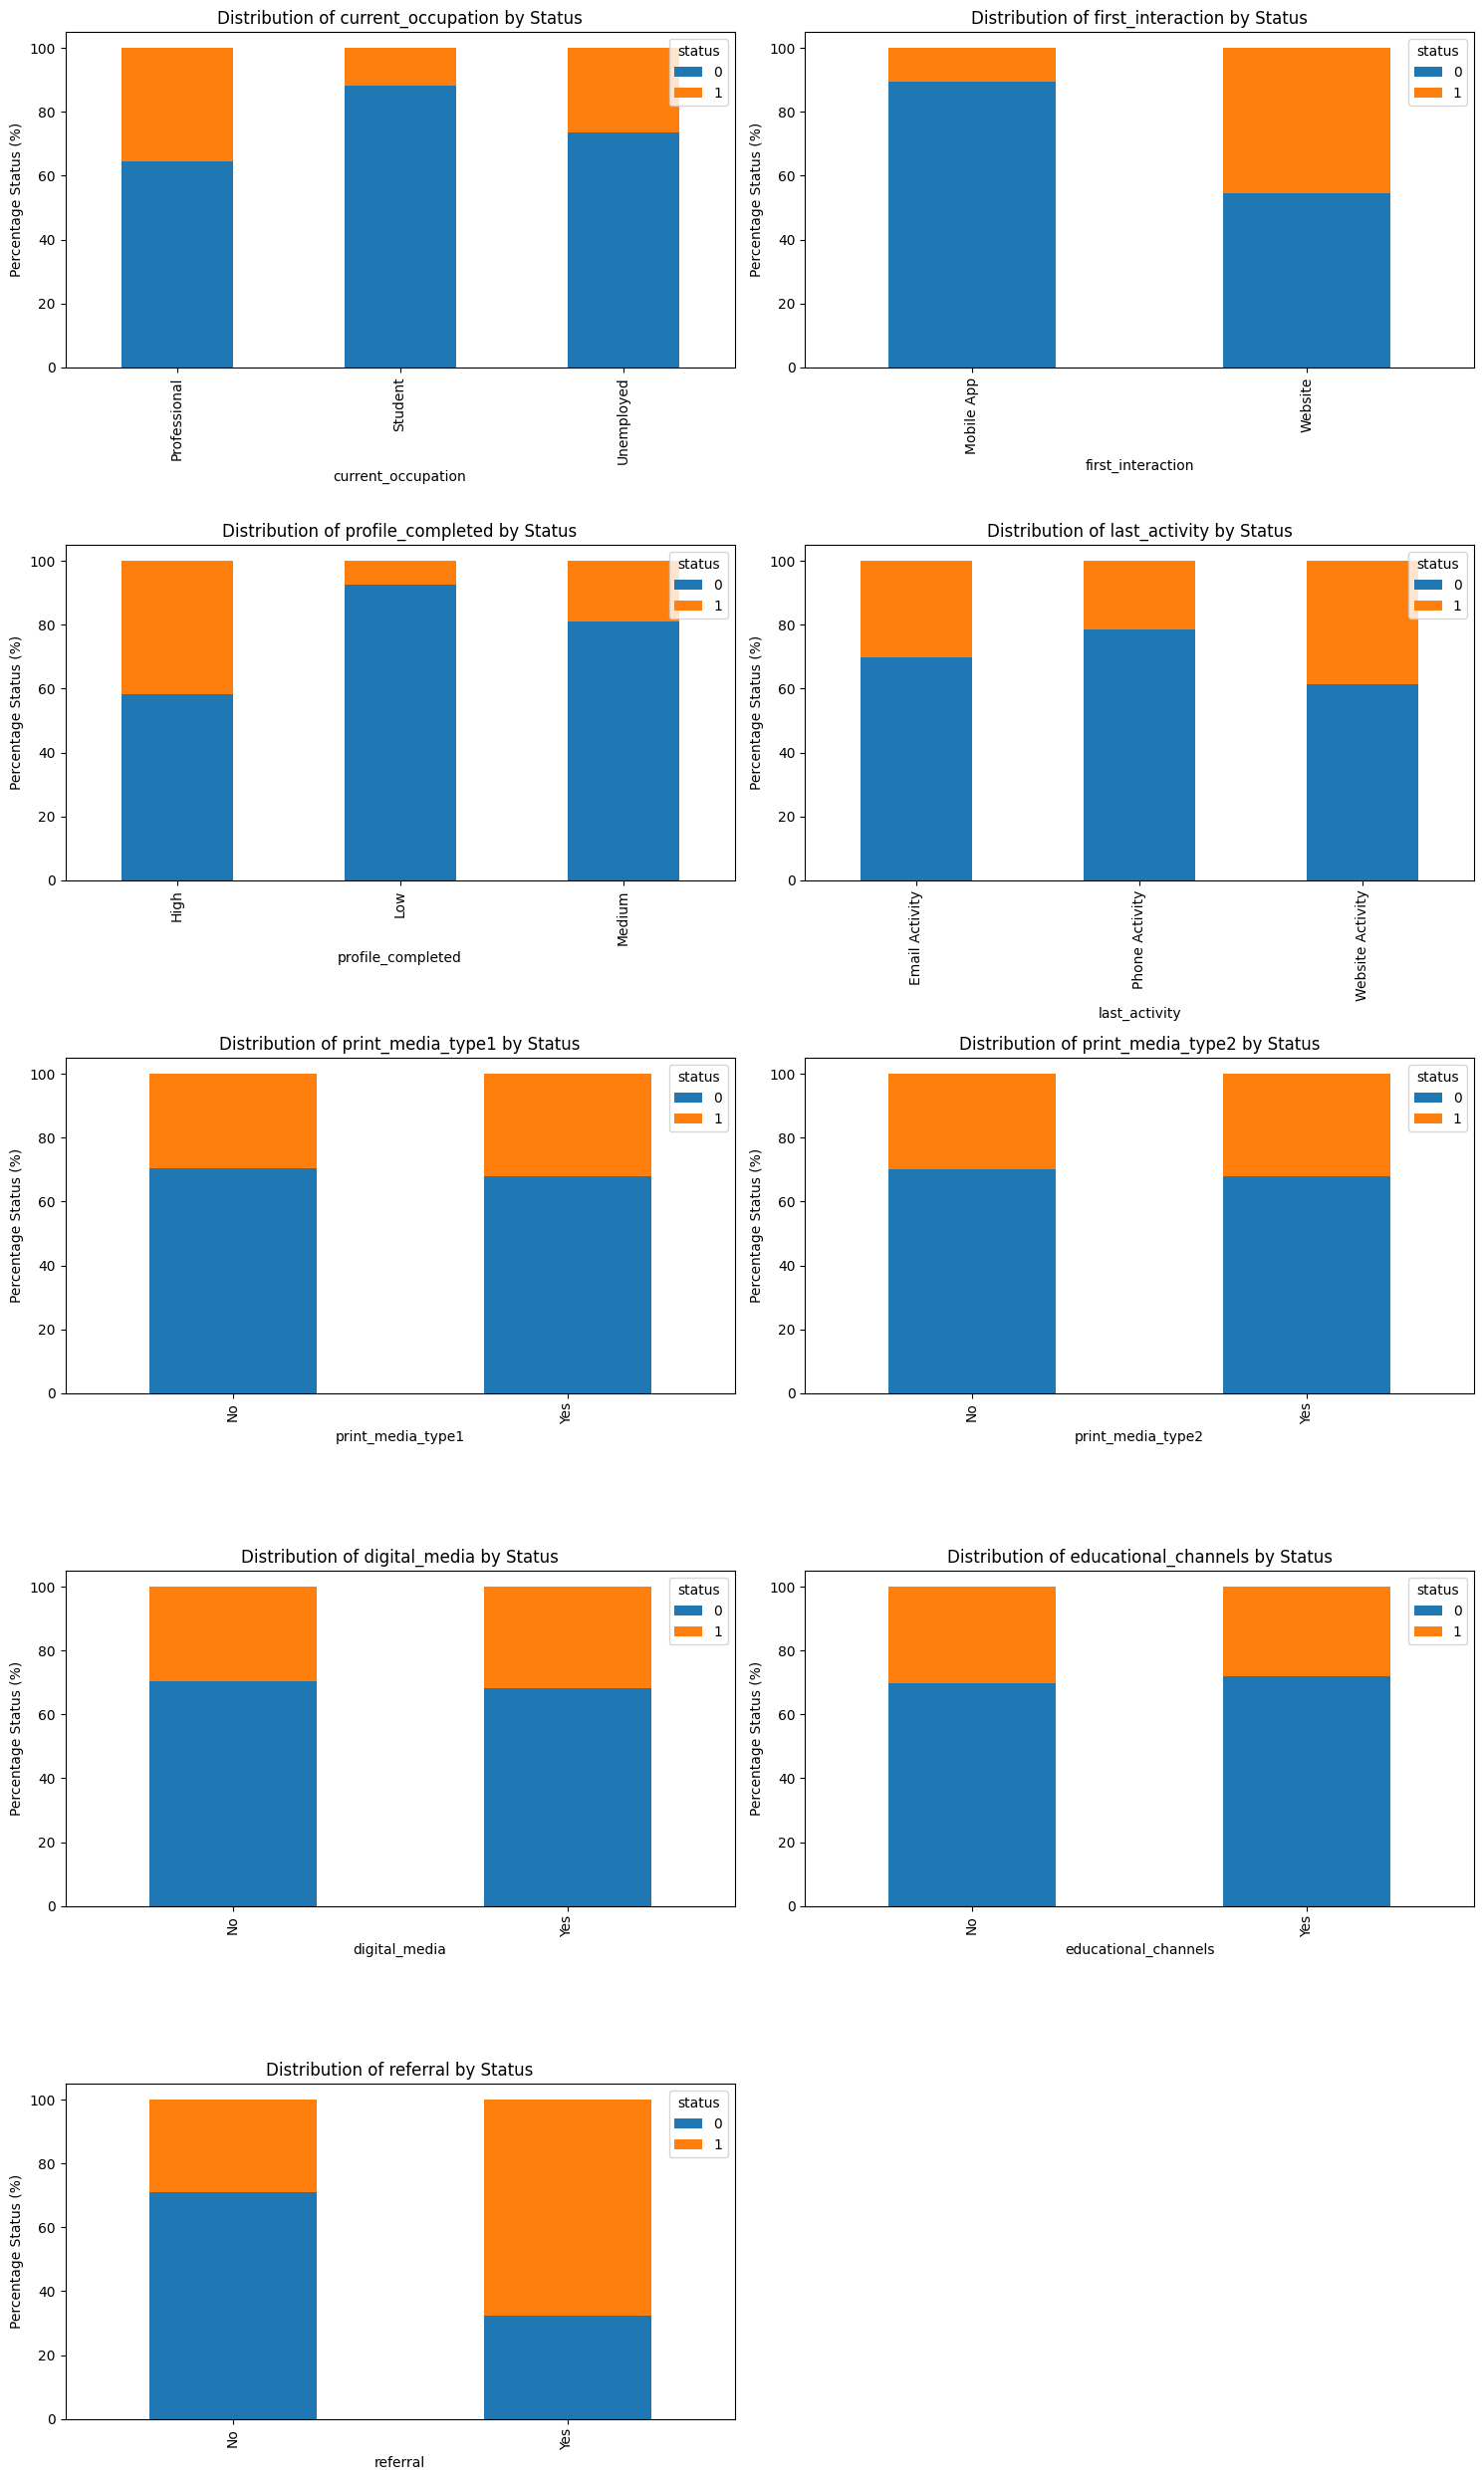

In [ ]:
# Bivariate analysis of categorical variables relative to status

# Create a list of categorical columns to plot, excluding 'status'
columns_to_plot = [col for col in categorical_columns if col != 'status']

num_plots = len(columns_to_plot)
num_rows = (num_plots + 1) // 2 # Calculate rows needed for 2 columns

fig, axes = plt.subplots(num_rows, 2, figsize=(15, 5 * num_rows))
axes = axes.flatten() # Flatten the array of axes for easy iteration

for idx, col_name in enumerate(columns_to_plot):
  (pd.crosstab(df[col_name], df['status'], normalize='index')*100).plot(kind='bar', stacked=True, ax=axes[idx])
  axes[idx].set_title(f'Distribution of {col_name} by Status')
  axes[idx].set_ylabel('Percentage Status (%)')
  axes[idx].set_xlabel(col_name)

# Hide any unused subplots if the number of plots is odd
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

# Observations


*   Print_media_type1, print_media_type2, and digital_media have no discernible impact on whether leads turned into paying customers as there is an equal percentage of leads who turned into paying customers in No (have not seen advertisement of ExtraaLearn) and Yes (have seen advertisement of ExtraaLearn) categories of all media types.


*   Referrals have been exceptionally effective for ExtraaLearn to obtain paying customers. Word of mouth from previous customers might be playing a big role into conversion of leads. This is shown by the fact that about 70% of the referred leads turned into paying customers which is the highest conversion for any of the categories.


*  Current_occupation drives the numbers of leads converted into paying customers. A higher percentage of leads who are already professionals turned into paying customers. This makes sense since proffesional might have more disposable income to spend on course with ExtraaLearn. Memmbers of this group could be looking for ways to increase their career opportunities also by pivoting into new roles in their current company or seeking jobs with other enteprises. The second group with highest percentage of paying customers is that of the unemployed. This could be because the group seeks to make themselves more employable by upskilling.

*   Significantly more leads who first interacted with extraaLearn through the Website (about 50%) turned into paying customers than those who initiated contact through the MobileApp (only 10%).It might be that the website is easier to navigate than the App and that the leads are better able to see all the important information about the company through the website.


*   last_activity by the leads is a good indicator of likelihood to convert into paying customers. The highest percentage of leads with Status 1 (paying customers) are those whose last activity was via website (website_activity). This is followed by leads under Email_acitivity category which lags behind Website_Activity by only 10%. This shows that ultimately leads get a lot of information through the company's website that might help them decide to enroll or that ExtraaLearn conducts most of its activities through the website. Email Activity has also been somewhat effective at turning leads into paying customers. This could be that leads who reach out to ExtraaLearn trhpugh email  might be very interested in program, hence likely to turn into paying customers given the right information. Leads who took no further action to interact with the company after a phone interaction with a company representative were less likely to be converted into paying customers.

*   The higher level of profile_completed correlates with the high number of leads who tuned into paying customers. This makes sense since paying customers are more likely to benefit from completing their profiles on the company's website. It could also mean that some leads filled their profiles initially since they were already determined to enroll because of a referral or personal research.












In [ ]:
df.groupby(['status'])[numerical_columns].mean()

,age,website_visits,time_spent_on_website,page_views_per_visit,status
status,,,,,
0,45.153014,3.578980,577.420711,3.025732,0.0
1,48.663762,3.538126,1068.397967,3.027050,1.0


# Observations



*   On average, status 1 leads spent almost double the amount of time on the company's website than status 0 leads (non-paying). This




<Axes: >

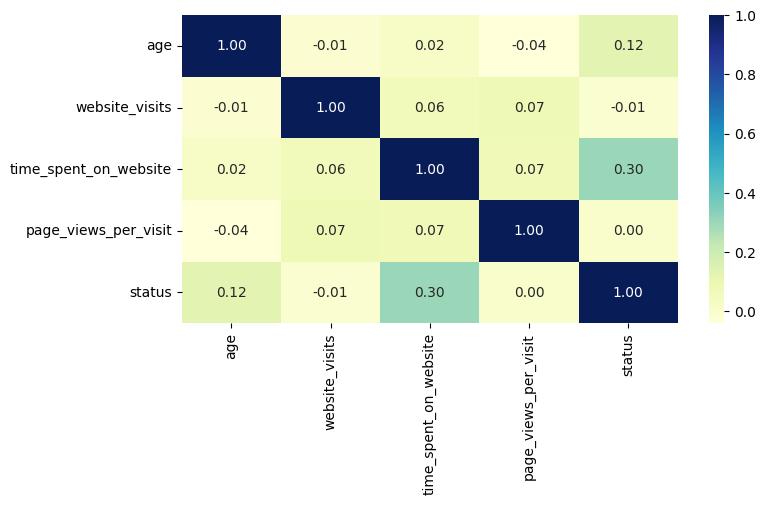

In [ ]:
# Plotting the correlation between numerical variables
plt.figure(figsize=(8,4))
sns.heatmap(df[numerical_columns].corr(),annot=True, fmt='0.2f', cmap='YlGnBu')

# Observations



*   Highest correlation between the numerical variables is 0.3 and is between time_spent_on_website and status. This makes sense since people who spend time on the website would acquire more information about the company and likely turn into paying customers.




## Building a Decision Tree model

# Preparing Data for the models

In [ ]:
# Re-initialize df and X for dummy creation.

X=df.drop('status', axis=1)

# Now, identify the categorical columns present in this freshly initialized X DataFrame
columns_to_dummify_in_X = X.select_dtypes(include='object').columns

# Create dummy variables for these identified categorical columns in X
X = pd.get_dummies(data=X, columns=columns_to_dummify_in_X, drop_first=True)

# Display the first few rows of the updated X DataFrame
display(X.head())

,age,website_visits,time_spent_on_website,page_views_per_visit,current_occupation_Student,current_occupation_Unemployed,first_interaction_Website,profile_completed_Low,profile_completed_Medium,last_activity_Phone Activity,last_activity_Website Activity,print_media_type1_Yes,print_media_type2_Yes,digital_media_Yes,educational_channels_Yes,referral_Yes
0,57,7,1639,1.861,False,True,True,False,False,False,True,True,False,True,False,False
1,56,2,83,0.320,False,False,False,False,True,False,True,False,False,False,True,False
2,52,3,330,0.074,False,False,True,False,True,False,True,False,False,True,False,False
3,53,4,464,2.057,False,True,True,False,False,False,True,False,False,False,False,False
4,23,4,600,16.914,True,False,True,False,False,False,False,False,False,False,False,False


Split data into training(70%) and test(30%) set.

In [ ]:
# Re-create Y from the original 'data' DataFrame to ensure it still contains status data

Y = data['status']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=1, stratify = Y)

In [ ]:
# write a function to calculate and print classification report and confusion matrix for both models
def metrics_score(actual , prediction):
    print(classification_report(actual, prediction))
    cm= confusion_matrix(actual, prediction)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.show()

## Decision Tree

In [ ]:
# Initialize the Decision Tree Classifier
dt_model = DecisionTreeClassifier( random_state=1)

# Fit the model to the training data
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(random_state=1)


Decision Tree Classifier Performance on Training Data:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2264
           1       1.00      1.00      1.00       964

    accuracy                           1.00      3228
   macro avg       1.00      1.00      1.00      3228
weighted avg       1.00      1.00      1.00      3228



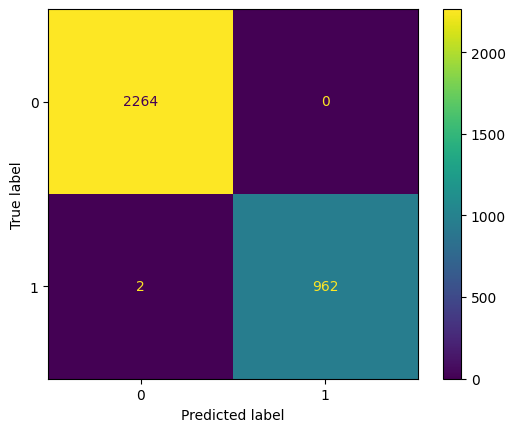

In [ ]:
y_train_predict_dt= dt_model.predict(x_train)
print('\nDecision Tree Classifier Performance on Training Data:')
metrics_score(y_train, y_train_predict_dt)


Decision Tree Classifier Performance on Test Data:
              precision    recall  f1-score   support

           0       0.86      0.87      0.86       971
           1       0.68      0.67      0.68       413

    accuracy                           0.81      1384
   macro avg       0.77      0.77      0.77      1384
weighted avg       0.81      0.81      0.81      1384



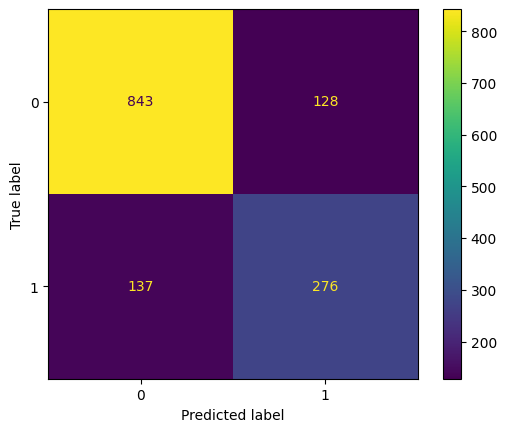

In [ ]:


# Make predictions on the test data
y_test_pred_dt = dt_model.predict(x_test)

# Evaluate the model using the custom metrics_score function
print('\nDecision Tree Classifier Performance on Test Data:')
metrics_score(y_test, y_test_pred_dt)

### Observations


*   The decision tree model results in 1 score for the training data which means that it is overfitting the training data

*   For the test data , the decision tree model correctly identified non-convert leads with  0.86 precision, has  a recall of 0.87  and an F1_score of 0.86. This model   

*   Applied to test data set, the mode perfoms moderately for the converted leads (Status 1) with a precision of 0.68, a recall of 0.67, and an F1-score of 0.68. There is 32% likelihood that the model will predict that a lead will convert into paying customer while in reality they won't. This could result in a big loss for ExtraaLearn.

*   Overal model accuracy for the test data is  0.81, which is lower compared to that of the training data. This model can be improved to perform better on test data, hence it needs pruning.



## Do we need to prune the tree?

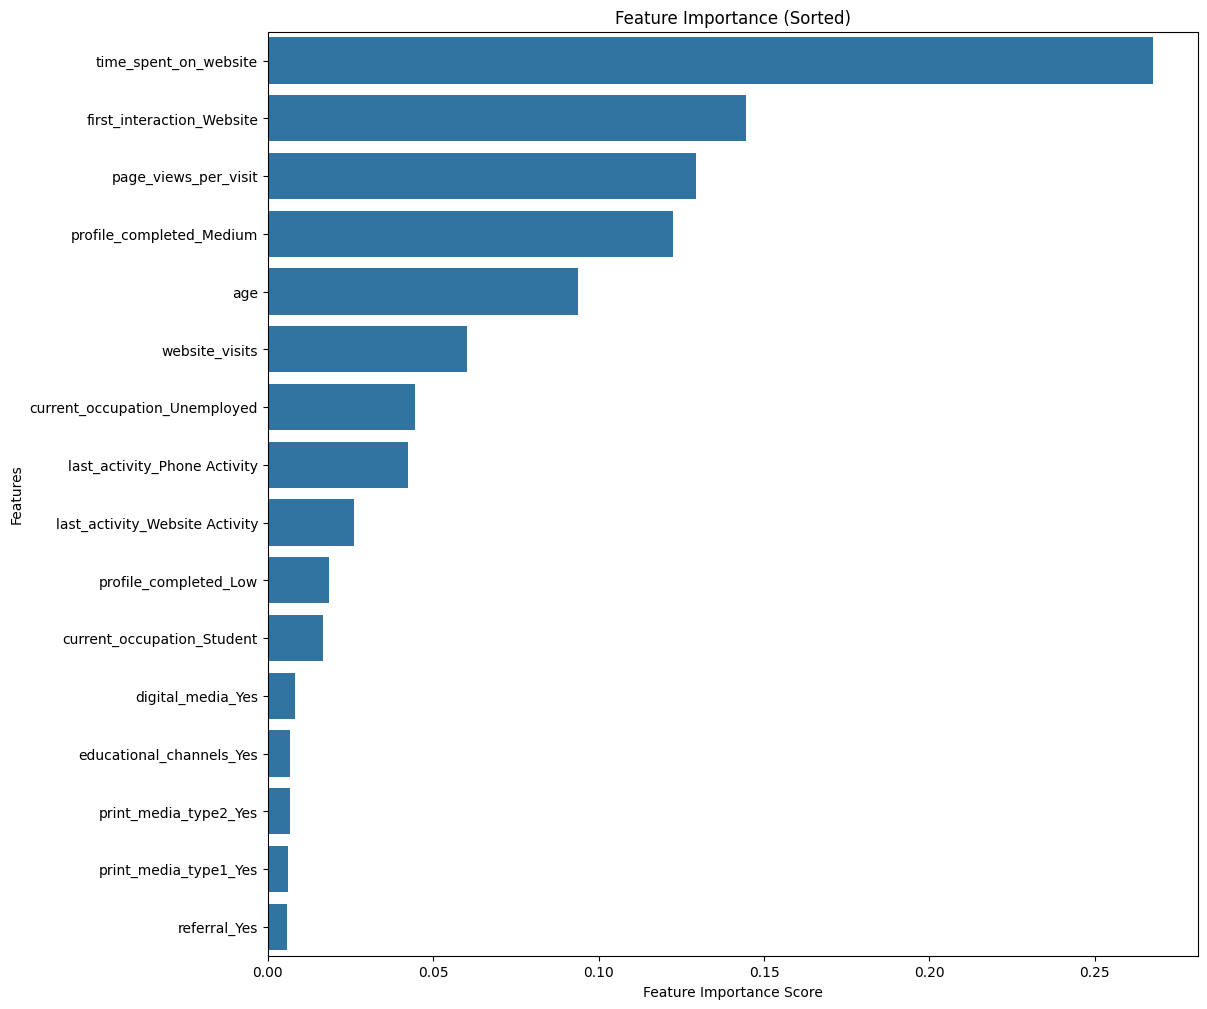

In [ ]:


# plot feature importance to determine what features aren't adding value on the model
importance = dt_model.feature_importances_
columns = X.columns
importance_df = pd.DataFrame(importance,index= columns, columns = ['Importance']).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(12,12))
sns.barplot(x=importance_df['Importance'], y=importance_df.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance (Sorted)')
plt.show()

## Observations


*   Lead feature in importance is the time_spent_on_website, which is followed by first_interaction_website, page_views_per_visit, profile_completed_medium and age. This signifies that leads website use behaviour and their age are the key indicators of whether they will convert into paying customers.

*   other important features are website_visits, current_occupation_unemployed, last_activity_Phone Activity, and last_activity_Website Activity



In [ ]:

# Calculate the effective alphas and impurities for pruning
path = dt_model.cost_complexity_pruning_path(x_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

print("Available ccp_alphas for pruning:", ccp_alphas[:10], "...") # Displaying first few for brevity

Available ccp_alphas for pruning: [0.00000000e+00 7.74473358e-05 8.09676693e-05 1.07286353e-04
 1.91774355e-04 1.99404635e-04 1.99642021e-04 2.06018793e-04
 2.06526229e-04 2.40160500e-04] ...


Now, let's train a Decision Tree Classifier for each of these `ccp_alpha` values and evaluate their performance on both the training and testing datasets.

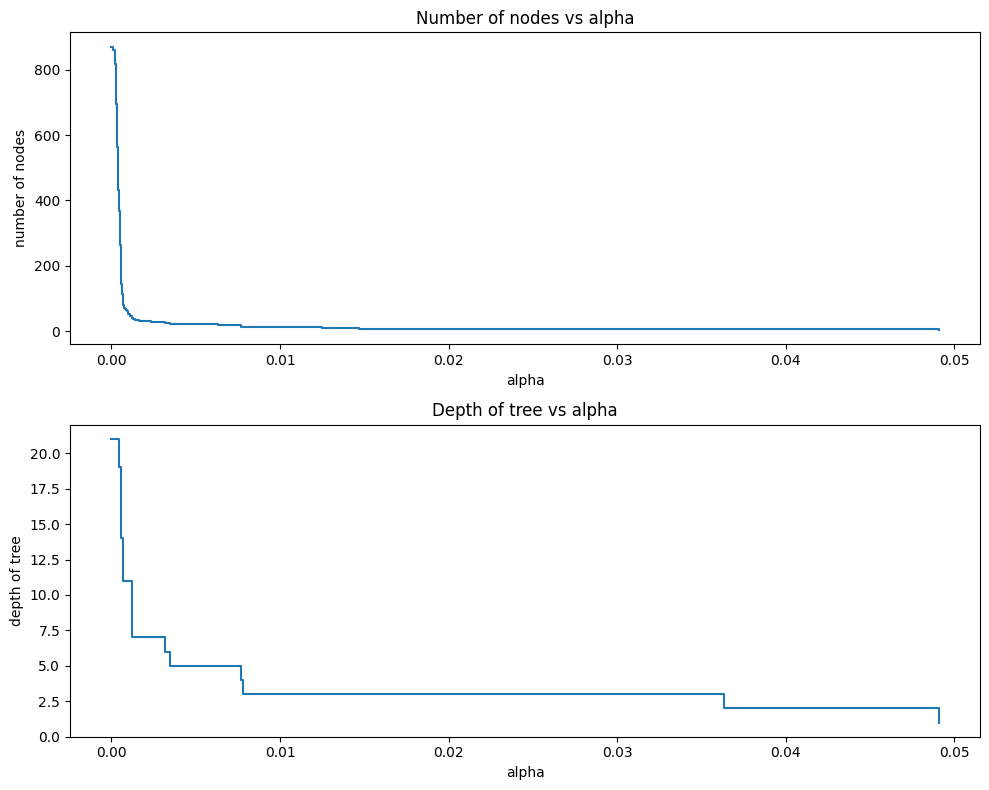

In [ ]:
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=1, ccp_alpha=ccp_alpha)
    clf.fit(x_train, y_train)
    clfs.append(clf)

# Remove the last element, which is the trivial tree with only one node
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]

fig, ax = plt.subplots(2, 1, figsize=(10, 8))
ax[0].plot(ccp_alphas, node_counts, drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth of tree vs alpha")
fig.tight_layout()
plt.show()

Let's plot the accuracy for both training and test sets as `ccp_alpha` changes to find the optimal pruning parameter.

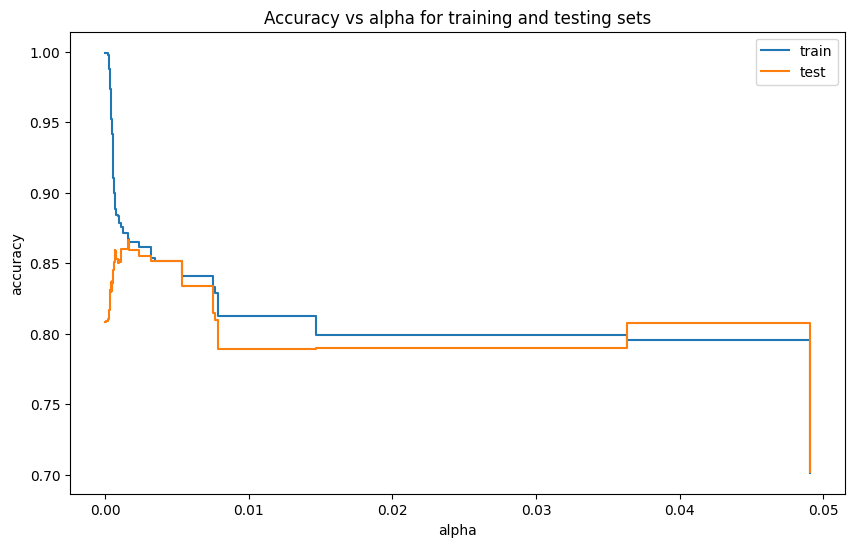

In [ ]:
train_scores = [clf.score(x_train, y_train) for clf in clfs]
test_scores = [clf.score(x_test, y_test) for clf in clfs]

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, label="test", drawstyle = "steps-post")
ax.legend()
plt.show()

From the plot, we can observe how accuracy changes with different `ccp_alpha` values. We are looking for the `ccp_alpha` value where the test accuracy is maximized. This usually indicates a good balance between bias and variance.

Based on the plot, we need to choose an optimal `ccp_alpha` to prune the tree. Let's find the `ccp_alpha` that gives the maximum test accuracy and then build the final pruned model.

Optimal ccp_alpha: 0.0015671843628937594

Pruned Decision Tree Classifier Performance on training data:
              precision    recall  f1-score   support

           0       0.88      0.93      0.91      2264
           1       0.82      0.71      0.76       964

    accuracy                           0.87      3228
   macro avg       0.85      0.82      0.83      3228
weighted avg       0.86      0.87      0.86      3228



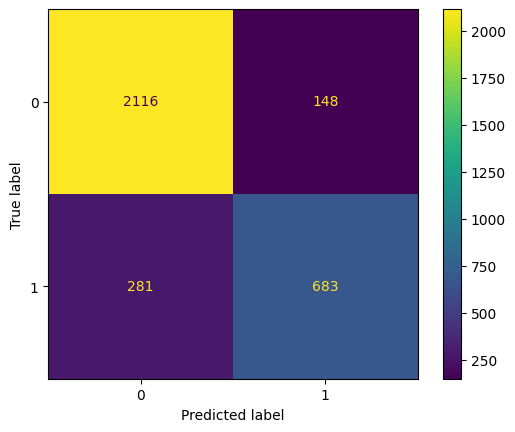


Pruned Decision Tree Classifier Performance on test data:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91       971
           1       0.84      0.69      0.75       413

    accuracy                           0.87      1384
   macro avg       0.86      0.81      0.83      1384
weighted avg       0.86      0.87      0.86      1384



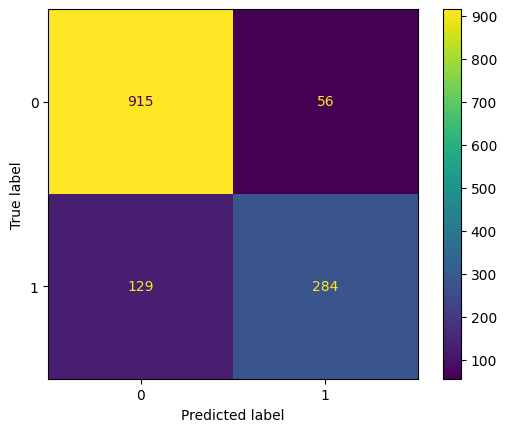

In [ ]:
# Find the optimal ccp_alpha that maximizes test accuracy
optimal_ccp_alpha_idx = np.argmax(test_scores)
optimal_ccp_alpha = ccp_alphas[optimal_ccp_alpha_idx]

print(f"Optimal ccp_alpha: {optimal_ccp_alpha}")

# Build the pruned Decision Tree model
dt_pruned = DecisionTreeClassifier(random_state=1, ccp_alpha=optimal_ccp_alpha)
dt_pruned.fit(x_train, y_train)

# Evaluate the pruned model
print('\nPruned Decision Tree Classifier Performance on training data:')
y_train_pred_pruned = dt_pruned.predict(x_train)
metrics_score(y_train, y_train_pred_pruned)

print('\nPruned Decision Tree Classifier Performance on test data:')
y_test_pred_pruned = dt_pruned.predict(x_test)
metrics_score(y_test, y_test_pred_pruned)

## Observations after pruning


*   Overall accuracy of the decision tree model is the same of the training and test datasets at about 0.87. The pruning helped eliminate overfitting in the training data and improved the accuracy on the test data from 0.81 originally to 0.87.

*   F-1 score for non-convert leads (status 0) for the DT classifier on the test data increased from 0.86 to 0.91. For the non-converts, the model performance improvement is mainly seen in recall from 0.86 to 0.94.


*   F-1 score for convert leads (status 1) for the DT on test data also increased from 0.68 to 0.75. For the converts, performance improvement is seen in precision from 0.68 to 0.84.

*  This model is much better performing than the previous one on the test dataset. However recall for Status 1 both on training and test data is the worse performing metric at 0.71 and 0.69 respectiviely. There is a 31% chance that the model will fail to identify status 1 leads as such.





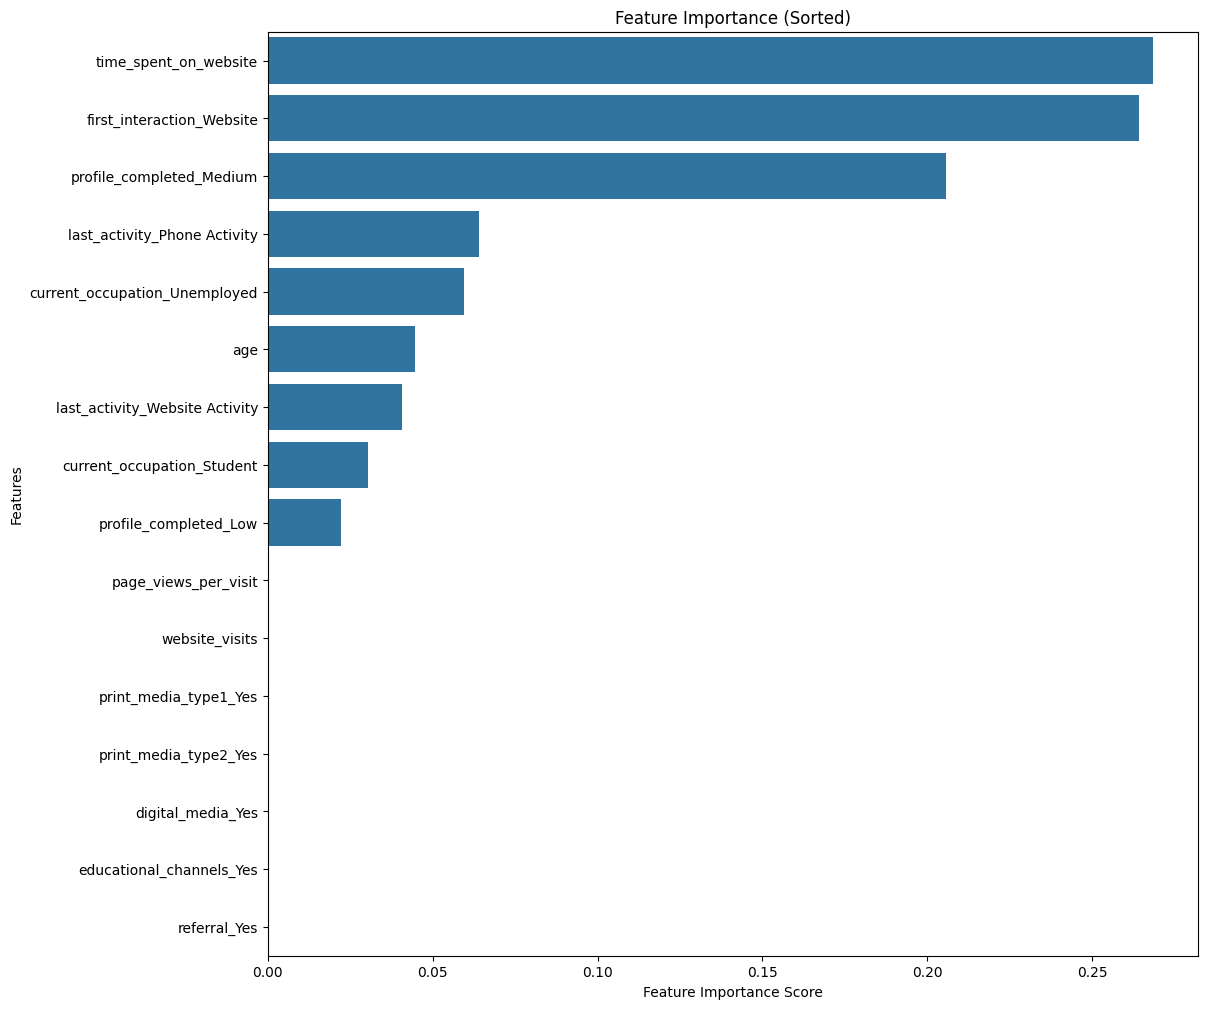

In [ ]:


# plot feature importance to determine what features aren't adding value on the model
importance = dt_pruned.feature_importances_
columns = X.columns
importance_df = pd.DataFrame(importance,index= columns, columns = ['Importance']).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(12,12))
sns.barplot(x=importance_df['Importance'], y=importance_df.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance (Sorted)')
plt.show()

### Observation on feature importance after pruning the decision tree


*   After pruning the decisio tree, the features of most importance are time_spent_on_website and first_interaction_Website, followed by profile_completed_medium.
*   Other important features are last_activity_Phone Activity, current-occupation_unemployed, age, last_activity_Website Activity, current_occupation_website Activity, current_occupation_Student, profile_completed_Low,



*   pruning made significant changes to the feature importance ranking, for example by dropping the website_visits and page_views_per_visit to no importance
*   List item





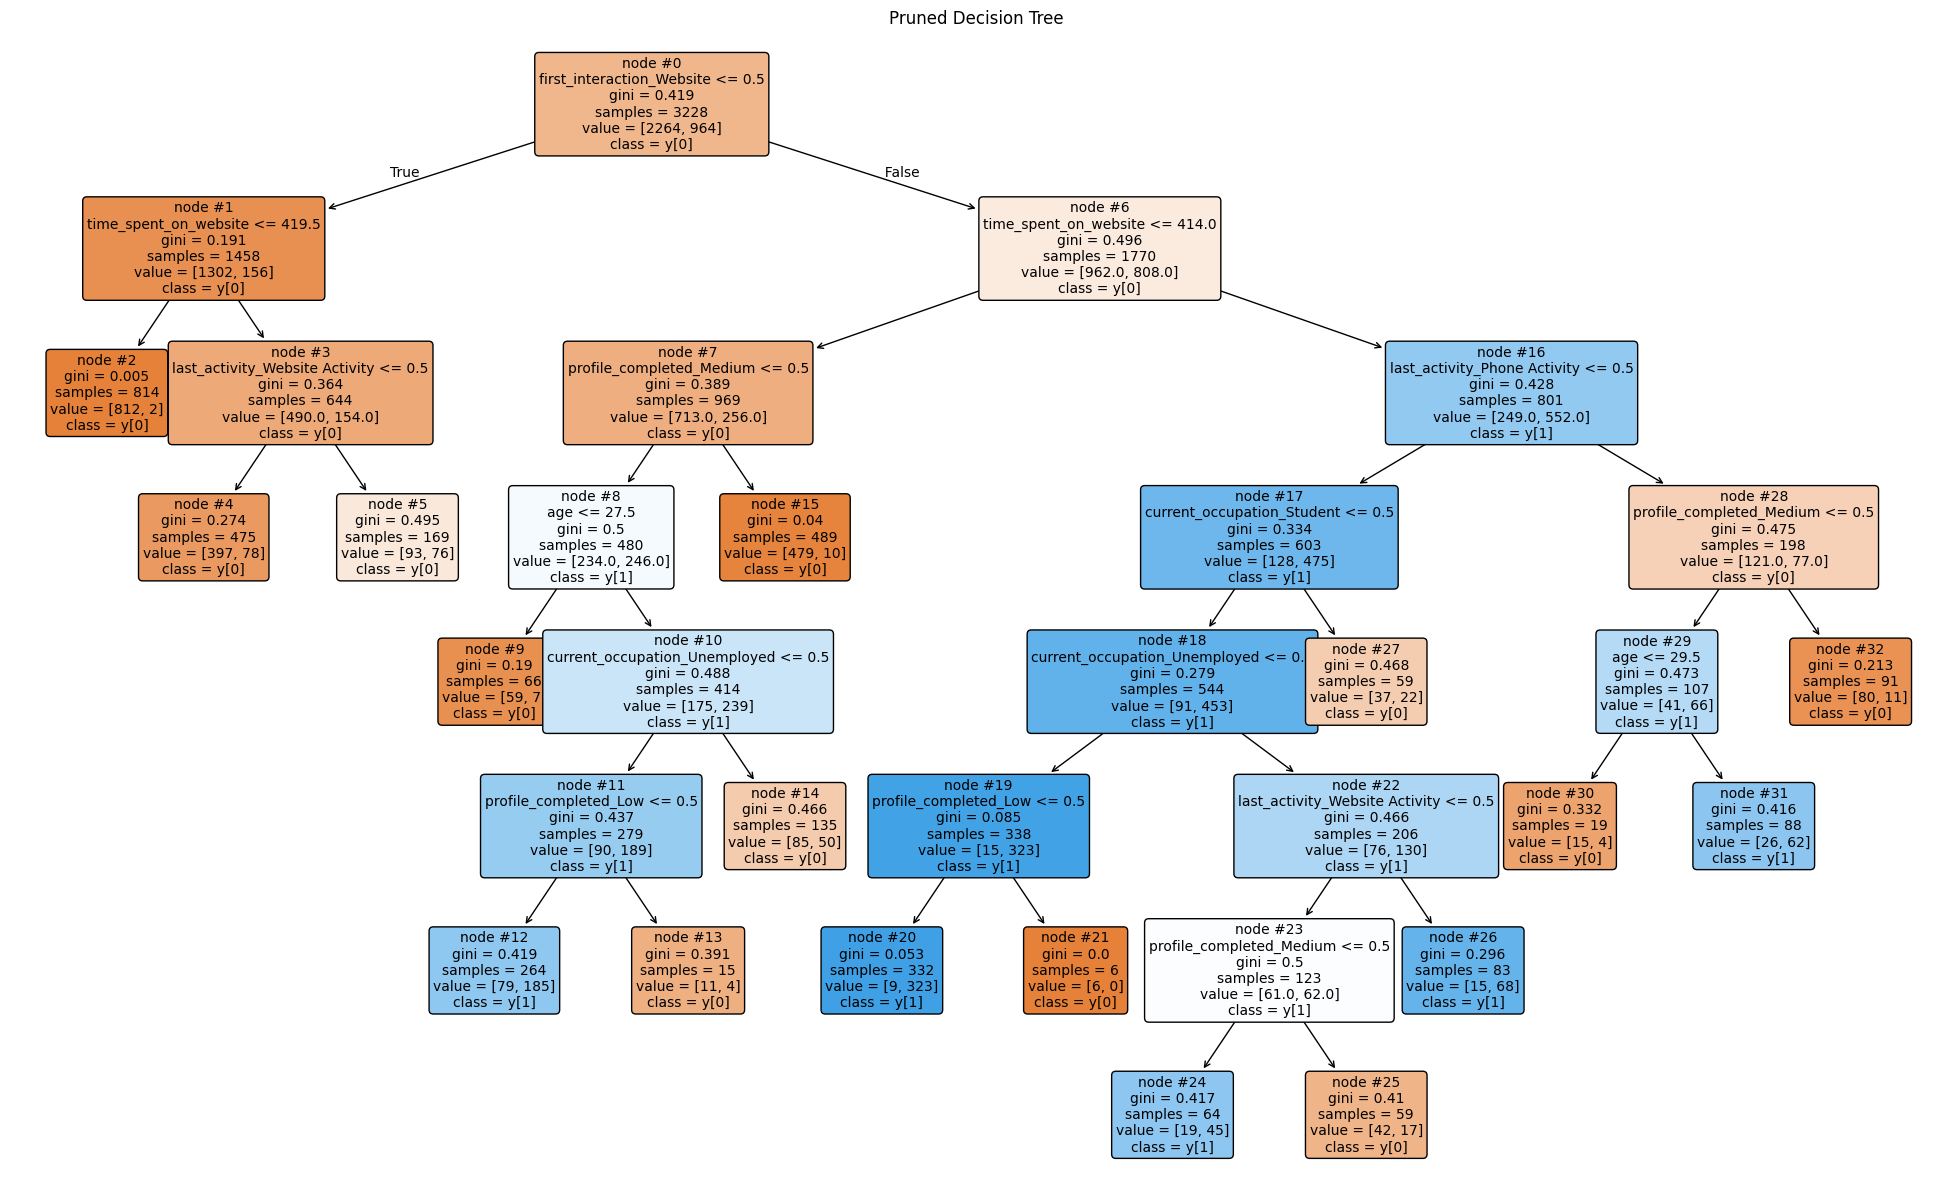

In [ ]:
# plot of the full pruned decision tree
plt.figure(figsize=(25, 15))
plot_tree(dt_pruned, feature_names=X.columns, filled=True, rounded=True, fontsize=10, node_ids = True, class_names = True)
plt.title('Pruned Decision Tree ')
plt.show()

### Observations on pruned decision tree classifier

The orange leaves represent  Status 0 (non-convert leads) class while blue leaves reprent status 1 (convert leads) class. The intensity of the color reflects the proportion of each status in the node. The darker the color the more dense the population of representative status is.

## Building a Random Forest model

Random Forest Classifier Performance on training data:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2264
           1       1.00      1.00      1.00       964

    accuracy                           1.00      3228
   macro avg       1.00      1.00      1.00      3228
weighted avg       1.00      1.00      1.00      3228



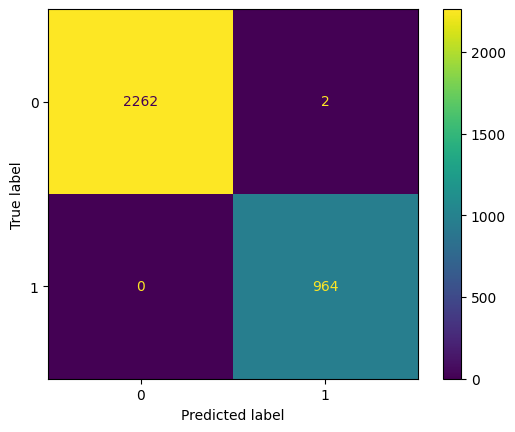


Random Forest Classifier Performance on test data:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90       971
           1       0.78      0.73      0.76       413

    accuracy                           0.86      1384
   macro avg       0.83      0.82      0.83      1384
weighted avg       0.86      0.86      0.86      1384



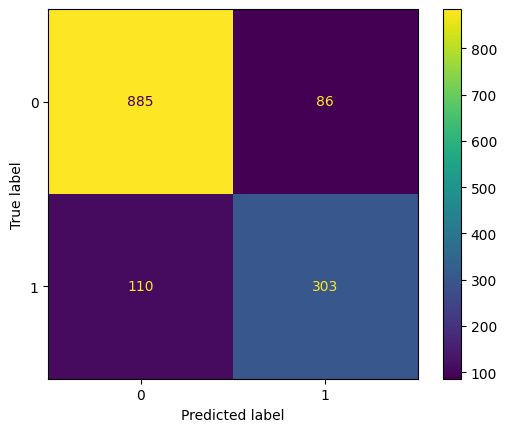

In [ ]:
# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(random_state=1)

# Fit the model to the training data
rf_model.fit(x_train, y_train)

print('Random Forest Classifier Performance on training data:')
y_train_pred_rf = rf_model.predict(x_train)
metrics_score(y_train, y_train_pred_rf)

print('\nRandom Forest Classifier Performance on test data:')
y_test_pred_rf = rf_model.predict(x_test)
metrics_score(y_test, y_test_pred_rf)

## Observations on Random Forest


*   Random Forest classifier is overfitting the training data with precision and recall of 1 on both status 0 and 1.
*   The RF classifier  has high precision (0.89) and recall (0.91) for status 0 leads


*   It has better recall of 0.73 compared to 0.69 of the pruned decision tree. The precision is slightly worse than the the pruned decision tree 0.78 compared to 0.84.

*   overall accuracy is practically the same of the random forest classifier 0.86 as the decision tree classier 0.87





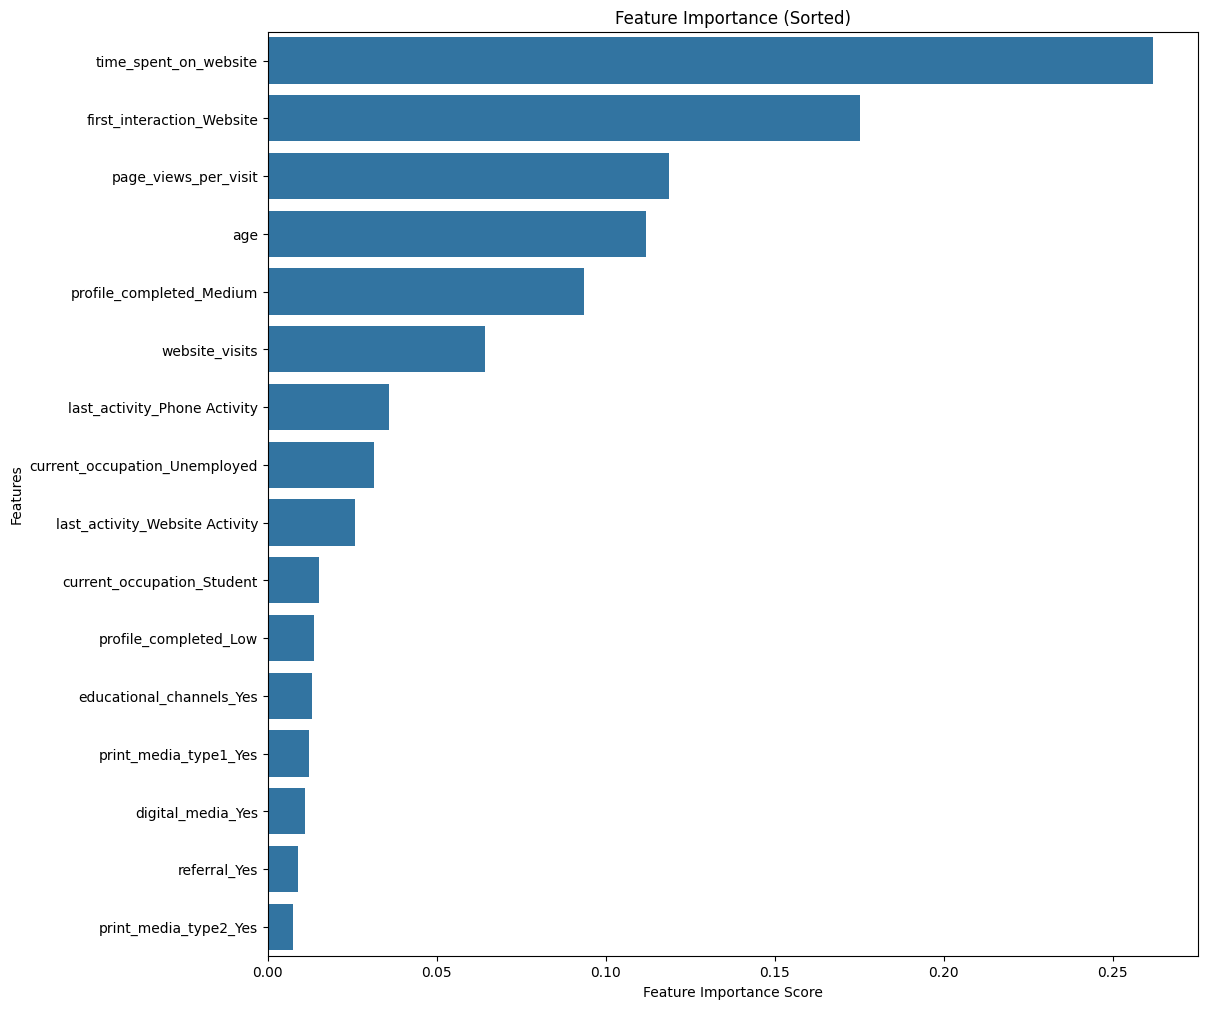

In [ ]:


# plot feature importance to determine what features aren't adding value on the model
importance = rf_model.feature_importances_
columns = X.columns
importance_df = pd.DataFrame(importance,index= columns, columns = ['Importance']).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(12,12))
sns.barplot(x=importance_df['Importance'], y=importance_df.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance (Sorted)')
plt.show()

### Observations on feature importance from Random Forest



*   random Forest mostly agrees with decision tree model on what features are important anf to what degree
*   There are differences on degree of importance of some features for random forest compared to pruned decision tree


*   time_spent_on_website is still the most important feature, followed by first_interaction_website. This further proves that leads who interact the most with content on the ExtraaLearn website are likely to convert into paying customers.

*   Other important features are page_views_per_visit, age, profile_completed_Medium, and website_visits.




## Do we need to prune the tree?

The Random Forest model is also overfitting the test data which means it could be immproved through tuning of hyperparameters.

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
# Define the parameter grid for Random Forest
param_grid = {
    'max_depth': [5, 10],   # range for maximum depth of the tree
    'min_samples_leaf': [2, 5, 10],    # range for minimum number of samples required to be at a leaf node
    'criterion': ['gini', 'entropy']  # Function to measure the quality of a split
}

In [ ]:
# Initialize a RandomForestClassifier model
rf = RandomForestClassifier(random_state=1)

In [ ]:
# Initialize GridSearchCV
# verbose=2 will print the progress of the grid search
# n_jobs=-1 will use all available CPU cores
# cv=3 means 3-fold cross-validation
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=2)

In [ ]:
# Fit the grid search to the training data
grid_search.fit(x_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=1), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'], 'max_depth': [5, 10],
                         'min_samples_leaf': [2, 5, 10]},
             scoring='f1', verbose=2)

In [ ]:
# Print the best parameters and the best score
print("\nBest parameters found: ", grid_search.best_params_)
print("Best f1 score found: ", grid_search.best_score_)


Best parameters found:  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5}
Best f1 score found:  0.7547039961758465


In [ ]:
# Get the best model from grid search
best_rf_model = grid_search.best_estimator_


Best Random Forest Classifier Performance on training data:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93      2264
           1       0.85      0.80      0.82       964

    accuracy                           0.90      3228
   macro avg       0.88      0.87      0.87      3228
weighted avg       0.90      0.90      0.90      3228



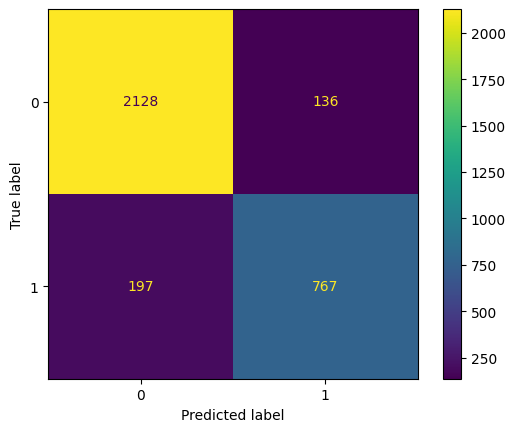

In [ ]:
print('\nBest Random Forest Classifier Performance on training data:')
y_train_pred_best_rf = best_rf_model.predict(x_train)
metrics_score(y_train, y_train_pred_best_rf)


Best Random Forest Classifier Performance on test data:
              precision    recall  f1-score   support

           0       0.89      0.92      0.91       971
           1       0.80      0.74      0.77       413

    accuracy                           0.87      1384
   macro avg       0.84      0.83      0.84      1384
weighted avg       0.86      0.87      0.86      1384



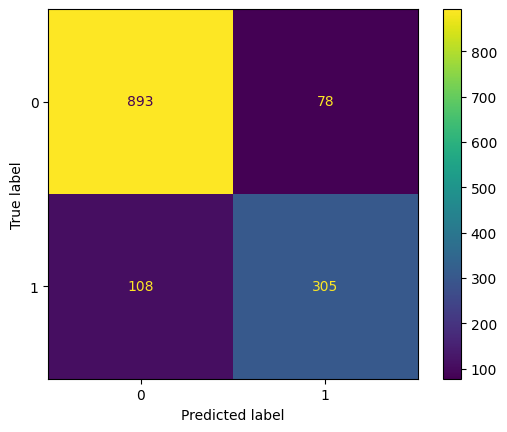

In [ ]:


# Evaluate the best model on the test data
print('\nBest Random Forest Classifier Performance on test data:')
y_test_pred_best_rf = best_rf_model.predict(x_test)
metrics_score(y_test, y_test_pred_best_rf)

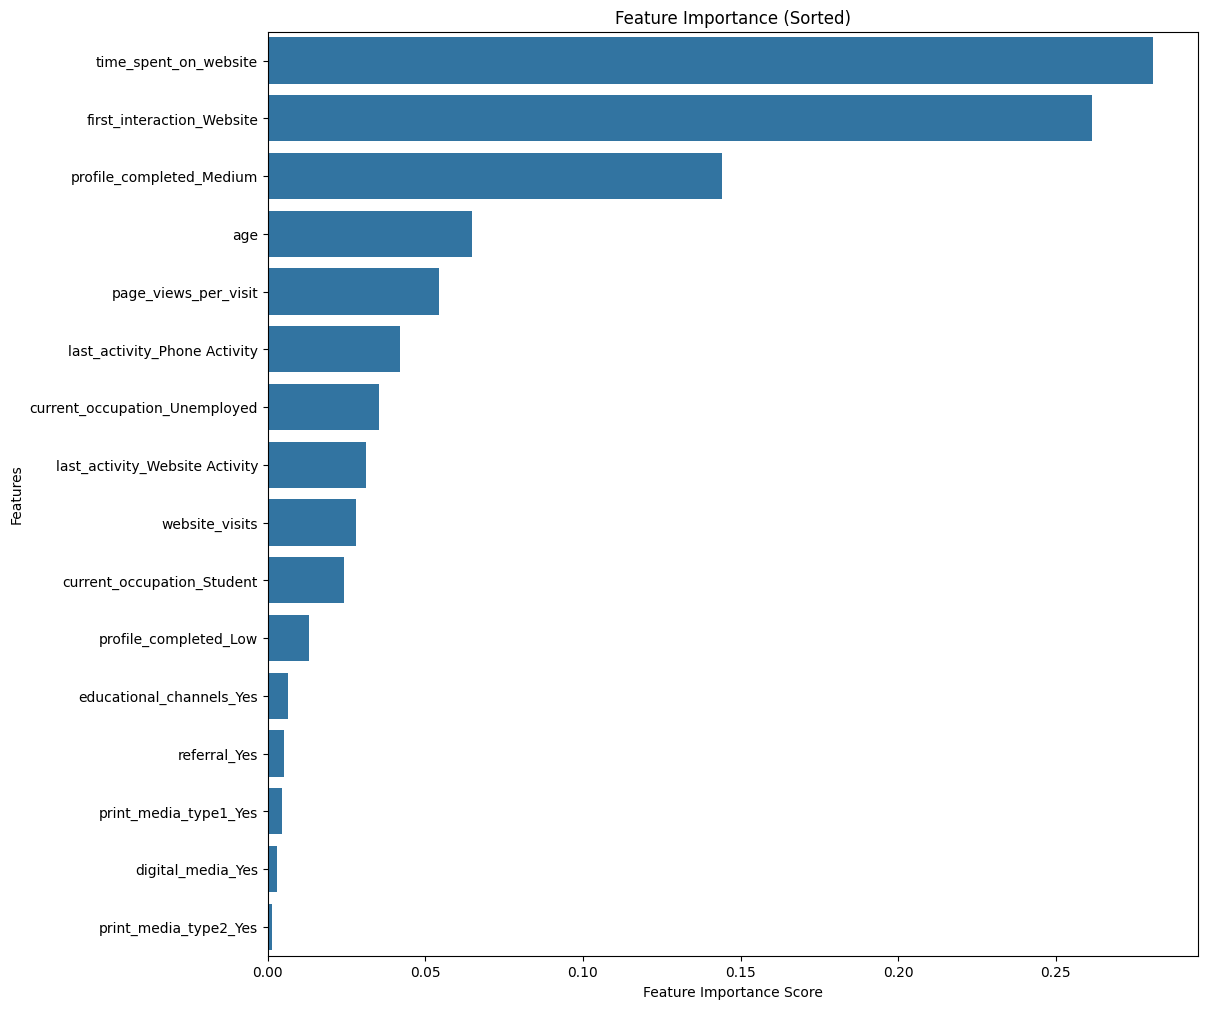

In [ ]:
# plot feature importance to determine what features aren't adding value on the model
importance = best_rf_model.feature_importances_
columns = X.columns
importance_df = pd.DataFrame(importance,index= columns, columns = ['Importance']).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(12,12))
sns.barplot(x=importance_df['Importance'], y=importance_df.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance (Sorted)')
plt.show()

### Observations on tuned Random Forest Model


*   The training accuracy (0.91) is higher than the test accuracy (0.87), and the F1-score for class 1 (converts) on the training data (0.85) is also higher than on the test data (0.77). This indicates that even with hyperparameter tuning, the Random Forest model is still overfitting, though not as severely as pre-tuning model.


*  For test data  on class 1 (convert leads), there is increased precision after tuning from 0.78 to 0.80, and recall from 0.73 to 0.74. Overall accuracy and F-1 score incread by 0.01.

*   Most benefit for tuning really appears to be in reduced overfitting of the training model.

*   There is a reshuffling of levels of importance of certain features like profile_completed_Medium whose elvel of importance went up and page_views_per_visit whose level of importance went down.





## Actionable Insights and Recommendations



*   Time spent the website and first_interaction_website are the most important features ofr nothe models. It means that by monitoring leads time on website the company can tell which leads are likely to convert into paying customers. Majority of leads who spend a lot of time on the website, who are under current_occupation_Unemployed and whose last_activity_Website Activity are likely to be status 1 leads or paying customers.

*   Also the company can try to increase leads traffic on the website since a high number of leads who first interacted with the company through the website turned into status 1 (converts).

*   Leads whose current_occupation is Unemployed and those who are older than 27.5 are likely to convert into paying customers (Status 1).ExtraaLearn might be doing a good job showing the value of upskilling/reskilling for gaining better job prospects.

*   The company can do a better job at connecting with the leads through phome interactions, especially for young students and unemployed whom they have not so far done good job of reaching outside their website. One way to achieve this is to train company representatives.


*   The company can build their website in such way that it appeals to students more by showing how they can still benefit from skills gained through ExtraaLearn.



